# Exploratory Data Analysis
### NFL Big Data Bowl 2027

By Chelle Davies

In [1]:
%pip install pandas numpy matplotlib seaborn plotly scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.3/20.3 MB 50.0 MB/s eta 0:00:0000:010:01

[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from IPython.display import display
import scipy
import scipy.stats as stats

In [3]:
# Load all CSV files in the "nfl-big-data-bowl-2027-data" directory into a dictionary of DataFrames

file_path = "nfl-big-data-bowl-2027-data"

dataframes = {
    os.path.splitext(filename)[0]: pd.read_csv(os.path.join(file_path, filename))
    for filename in os.listdir(file_path)
    if filename.lower().endswith(".csv")
}

list(dataframes)

['combine_results',
 'game_tracking_2024',
 'combine_tracking',
 'game_tracking_2025',
 'game_tracking_2023',
 'players',
 'games',
 'player_play',
 'player_career_successes']

### Previewing the Data Set

#### Player Features

In [4]:
players_df = dataframes["players"]
player_play_df = dataframes["player_play"]
player_career_success_df = dataframes["player_career_successes"]

In [5]:
display(players_df.head())
display(player_play_df.head())
display(player_career_success_df.head())

,nfl_id,display_name,draft_year,nfl_position,birth_date,college_name,college_conference,draft_round,draft_pick_within_round,draft_overall_pick
0,55867,Will Anderson,2023,DE,2001-09-02,Alabama,Southeastern Conference,1.0,3.0,3.0
1,55870,Paris Johnson,2023,T,2001-07-31,Ohio State,Big Ten Conference,1.0,6.0,6.0
2,55874,Darnell Wright,2023,T,2001-08-10,Tennessee,Southeastern Conference,1.0,10.0,10.0
3,55875,Peter Skoronski,2023,G,2001-07-31,Northwestern,Big Ten Conference,1.0,11.0,11.0
4,55877,Lukas Van Ness,2023,DE,2001-07-06,Iowa,Big Ten Conference,1.0,13.0,13.0


,game_id,play_id,team_abbr,nfl_id,lined_up_position,play_description,quarter,down,yards_to_go,possession_team,...,sack,tackle,assist,caused_forced_fumble,recovered_fumble,tackle_for_loss,time_to_pressure,time_to_qb_hurry,coverage_assignment,coverage_assignment_at_snap
0,2025111610,2279,BAL,57183,T,(8:42) (Shotgun) L.Jackson pass incomplete dee...,3,1,10,BAL,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026011701,1626,SF,58248,INTERIOR_LINE,(3:48) (Shotgun) K.Walker left end to SEA 28 f...,2,2,7,SEA,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2025101900,2838,LAR,57140,EDGE,(7:01) C.Van Lanen reported in as eligible. T...,3,2,2,JAX,...,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NO_ASSIGNMENT,NO_ASSIGNMENT
3,2025111300,2628,NYJ,58209,T,(4:05) I.Williams left end to NE 22 for 4 yard...,3,1,10,NYJ,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2025121406,2653,NYG,57191,OLB,"(10:08) (No Huddle, Shotgun) M.Mariota scrambl...",3,2,10,WAS,...,0.0,1.0,0.0,0.0,NaN,False,NaN,NaN,HOOK_CURL_LEFT,CURL_FLAT_LEFT


,nfl_id,career_offensive_snaps,career_defensive_snaps,career_special_teams_snaps,career_games_active,career_games_started,ap_all_pro_1st_team,ap_all_pro_2nd_team,pro_bowl_original_ballot
0,55867,0,1884,92,51,44,1,0,1
1,55870,2802,0,169,47,43,0,0,0
2,55874,3222,0,167,51,49,0,1,0
3,55875,3011,0,170,51,48,0,0,0
4,55877,0,1056,387,51,2,0,0,0


In [ ]:
# Player performance analysis using the existing player and career-success datasets

# 1) Merge player metadata with career performance
player_perf = players_df.merge(player_career_success_df, on="nfl_id", how="left")

# Fill missing values for metrics that are naturally zero for a player with no recorded activity
numeric_cols = [
    "career_offensive_snaps", "career_defensive_snaps", "career_special_teams_snaps",
    "career_games_active", "career_games_started",
    "ap_all_pro_1st_team", "ap_all_pro_2nd_team", "pro_bowl_original_ballot"
]
for col in numeric_cols:
    player_perf[col] = pd.to_numeric(player_perf[col], errors="coerce").fillna(0)

# Create summary metrics
player_perf["total_snaps"] = (
    player_perf["career_offensive_snaps"]
    + player_perf["career_defensive_snaps"]
    + player_perf["career_special_teams_snaps"]
)

player_perf["award_points"] = (
    10 * player_perf["ap_all_pro_1st_team"]
    + 5 * player_perf["ap_all_pro_2nd_team"]
    + 3 * player_perf["pro_bowl_original_ballot"]
)

# Composite performance score: weighted toward total snaps, games played/started, and awards
max_total_snaps = player_perf["total_snaps"].max()
max_games_active = player_perf["career_games_active"].max()
max_games_started = player_perf["career_games_started"].max()
max_awards = player_perf["award_points"].max()

player_perf["performance_score"] = (
    (player_perf["total_snaps"] / max_total_snaps) * 50 +
    (player_perf["career_games_active"] / max_games_active) * 20 +
    (player_perf["career_games_started"] / max_games_started) * 15 +
    (player_perf["award_points"] / max_awards) * 15
)

In [7]:
# 2) Show the highest-performing players
top_players = player_perf.sort_values("performance_score", ascending=False).head(15)

columns_to_show = [
    "display_name", "nfl_position", "draft_year", "total_snaps",
    "career_games_active", "career_games_started",
    "ap_all_pro_1st_team", "ap_all_pro_2nd_team", "pro_bowl_original_ballot",
    "performance_score"
]

print("Top 15 players by composite performance score:")
display(top_players[columns_to_show])

Top 15 players by composite performance score:


,display_name,nfl_position,draft_year,total_snaps,career_games_active,career_games_started,ap_all_pro_1st_team,ap_all_pro_2nd_team,pro_bowl_original_ballot,performance_score
2,Darnell Wright,T,2023,3389,51,49,0,1,0,85.990381
30,O'Cyrus Torrence,G,2023,3551,51,50,0,0,0,85.000000
14,Matthew Bergeron,G,2023,3352,51,49,0,0,0,81.897972
11,Anton Harrison,T,2023,3209,51,48,0,0,0,79.584455
3,Peter Skoronski,G,2023,3181,51,48,0,0,0,79.190200
85,Puka Nacua,WR,2023,2222,46,43,1,1,2,77.226177
26,Tuli Tuipulotu,OLB,2023,3014,51,36,0,0,1,75.381607
39,Byron Young,OLB,2023,2723,51,49,0,0,1,75.184169
7,Jaxon Smith-Njigba,WR,2023,2447,51,36,1,0,1,74.540797
1,Paris Johnson,T,2023,2971,47,43,0,0,0,73.164659


In [8]:
# 3) Overall performance by position
position_summary = (
    player_perf.groupby("nfl_position")
    .agg(
        players=("nfl_id", "count"),
        avg_total_snaps=("total_snaps", "mean"),
        avg_games_active=("career_games_active", "mean"),
        avg_games_started=("career_games_started", "mean"),
        avg_performance_score=("performance_score", "mean"),
        avg_awards=("award_points", "mean")
    )
    .sort_values("avg_performance_score", ascending=False)
)

print("\nAverage performance by position:")
display(position_summary)


Average performance by position:


,players,avg_total_snaps,avg_games_active,avg_games_started,avg_performance_score,avg_awards
nfl_position,,,,,,
SS,28,977.142857,25.500000,10.071429,26.856659,0.107143
G,51,838.607843,21.392157,11.627451,23.685368,0.000000
OLB,30,775.300000,24.400000,7.800000,23.110985,0.400000
T,50,784.480000,19.840000,11.200000,22.300580,0.160000
CB,60,755.850000,22.400000,7.783333,21.916852,0.216667
DE,36,656.388889,26.055556,5.777778,21.451445,0.361111
RB,1,524.000000,34.000000,0.000000,20.711537,0.000000
WR,106,634.132075,22.226415,7.339623,20.271579,0.594340
C,20,604.100000,23.250000,8.650000,20.218702,0.000000


/var/folders/gr/6ytyl_l54r34xk4zb10_hq680000gn/T/ipykernel_82542/1815724210.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


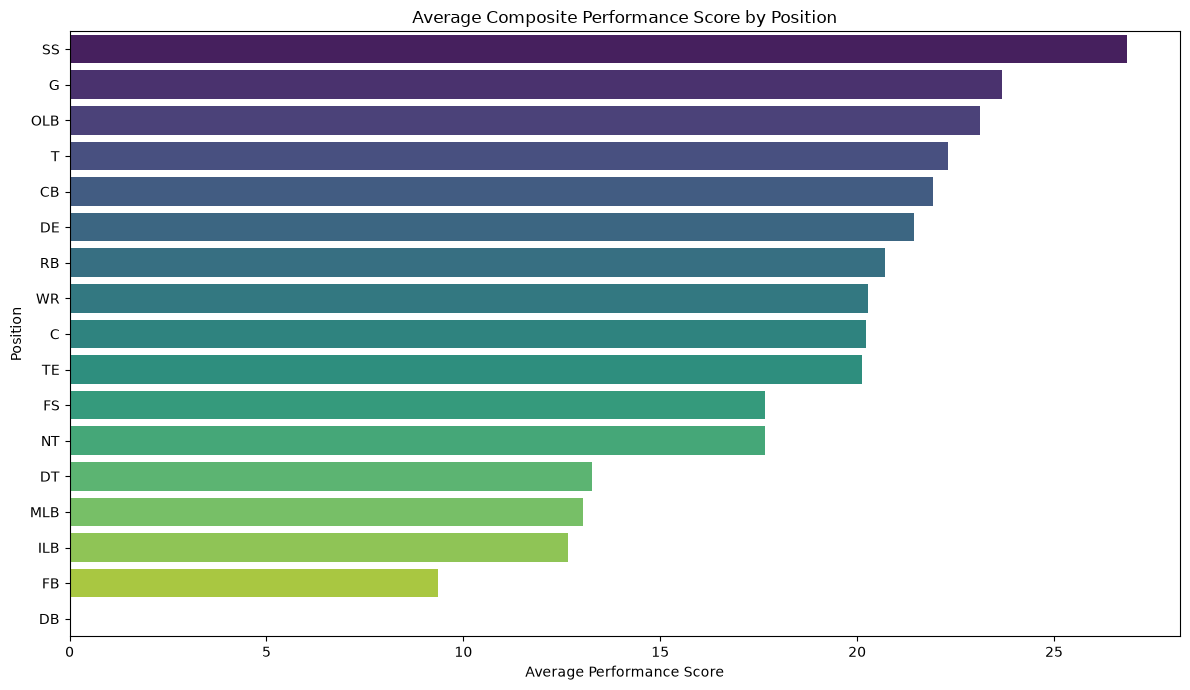

In [9]:
# 4) Plot average performance by position
plt.figure(figsize=(12, 7))
sns.barplot(
    data=position_summary.reset_index(),
    x="avg_performance_score",
    y="nfl_position",
    palette="viridis"
)
plt.title("Average Composite Performance Score by Position")
plt.xlabel("Average Performance Score")
plt.ylabel("Position")
plt.tight_layout()
plt.show()

In [10]:
# 5) Simple correlation check: does higher total snap count align with awards?
corr = player_perf[["total_snaps", "award_points", "performance_score"]].corr()
print("\nCorrelation matrix among snaps, awards, and performance score:")
display(corr)


Correlation matrix among snaps, awards, and performance score:


,total_snaps,award_points,performance_score
total_snaps,1.000000,0.223597,0.980950
award_points,0.223597,1.000000,0.285884
performance_score,0.980950,0.285884,1.000000


In [11]:
# 6) Save a cleaned leaderboard for later use
player_leaderboard = player_perf.sort_values("performance_score", ascending=False).reset_index(drop=True)
player_leaderboard = player_leaderboard[columns_to_show]

print("\nSaved leaderboard as: player_leaderboard")


Saved leaderboard as: player_leaderboard


In [12]:
display(player_leaderboard)

,display_name,nfl_position,draft_year,total_snaps,career_games_active,career_games_started,ap_all_pro_1st_team,ap_all_pro_2nd_team,pro_bowl_original_ballot,performance_score
0,Darnell Wright,T,2023,3389,51,49,0,1,0,85.990381
1,O'Cyrus Torrence,G,2023,3551,51,50,0,0,0,85.000000
2,Matthew Bergeron,G,2023,3352,51,49,0,0,0,81.897972
3,Anton Harrison,T,2023,3209,51,48,0,0,0,79.584455
4,Peter Skoronski,G,2023,3181,51,48,0,0,0,79.190200
...,...,...,...,...,...,...,...,...,...,...
505,Lonnie Phelps,DE,2023,0,0,0,0,0,0,0.000000
506,D.J. Dale,DT,2023,0,0,0,0,0,0,0.000000
507,Zah Frazier,CB,2025,0,0,0,0,0,0,0.000000
508,Emil Ekiyor,G,2023,0,0,0,0,0,0,0.000000


In [13]:
# Engineer additional performance features from player-play data
play_df = player_play_df.copy()

In [14]:
# Convert available event and production columns to numeric
sum_features = {
    "target": "targets",
    "rec_yards": "receiving_yards",
    "rush_yards": "rushing_yards",
    "sack": "sacks",
    "tackle": "tackles",
    "assist": "assists",
    "tackle_for_loss": "tackles_for_loss",
    "caused_forced_fumble": "forced_fumbles",
}
available_sum_features = {
    source: output
    for source, output in sum_features.items()
    if source in play_df.columns
}

for column in available_sum_features:
    play_df[column] = pd.to_numeric(play_df[column], errors="coerce")

In [15]:
# Aggregate player-level production
play_features = (
    play_df.groupby("nfl_id")[list(available_sum_features)]
    .sum(min_count=1)
    .rename(columns=available_sum_features)
)

# Add play participation and receiving catch estimates when available
play_features["tracked_plays"] = play_df.groupby("nfl_id").size()

if "rec_yards" in play_df.columns:
    play_features["receptions_est"] = (
        play_df["rec_yards"].notna().groupby(play_df["nfl_id"]).sum()
    )

In [16]:
# Merge with the existing career and performance features
player_perf_extended = player_perf.merge(
    play_features,
    on="nfl_id",
    how="left"
)

feature_columns = [
    column for column in
    ["targets", "receiving_yards", "rushing_yards", "sacks", "tackles",
     "assists", "tackles_for_loss", "forced_fumbles", "receptions_est",
     "tracked_plays"]
    if column in player_perf_extended.columns
]
player_perf_extended[feature_columns] = (
    player_perf_extended[feature_columns].fillna(0)
)

In [17]:
# Efficiency features; zero-denominator cases remain missing
if {"receiving_yards", "targets"}.issubset(player_perf_extended.columns):
    player_perf_extended["receiving_yards_per_target"] = (
        player_perf_extended["receiving_yards"]
        .div(player_perf_extended["targets"].replace(0, np.nan))
    )

if {"receptions_est", "targets"}.issubset(player_perf_extended.columns):
    player_perf_extended["estimated_catch_rate"] = (
        player_perf_extended["receptions_est"]
        .div(player_perf_extended["targets"].replace(0, np.nan))
    )

In [18]:
# Review new features alongside the existing composite score
new_features = [
    column for column in
    ["receiving_yards", "rushing_yards", "sacks", "tackles",
     "tackles_for_loss", "forced_fumbles", "receiving_yards_per_target",
     "estimated_catch_rate"]
    if column in player_perf_extended.columns
]

feature_correlations = (
    player_perf_extended[new_features + ["performance_score"]]
    .corr(method="spearman")["performance_score"]
    .drop("performance_score")
    .sort_values(ascending=False)
)

print("Spearman correlation with the existing performance score:")
display(feature_correlations.to_frame("spearman_correlation"))

Spearman correlation with the existing performance score:


,spearman_correlation
tackles,0.391837
forced_fumbles,0.332132
tackles_for_loss,0.282017
receiving_yards_per_target,0.272641
estimated_catch_rate,0.268388
sacks,0.258534
receiving_yards,0.125983
rushing_yards,0.016450


In [19]:
# Show leaders for selected role-specific features
for feature in ["receiving_yards", "rushing_yards", "sacks", "tackles"]:
    if feature in player_perf_extended.columns:
        print(f"\nTop players by {feature.replace('_', ' ')}:")
        display(
            player_perf_extended[
                ["display_name", "nfl_position", feature, "performance_score"]
            ]
            .sort_values(feature, ascending=False)
            .head(10)
        )


Top players by receiving yards:


,display_name,nfl_position,receiving_yards,performance_score
85,Puka Nacua,WR,4877.0,77.226177
7,Jaxon Smith-Njigba,WR,3872.0,74.540797
9,Jordan Addison,WR,2487.0,65.691257
27,Rashee Rice,WR,2262.0,34.534630
177,Ladd McConkey,WR,2189.0,43.803004
44,Michael Wilson,WR,2135.0,66.080372
170,Brian Thomas,WR,2119.0,44.313057
23,Jayden Reed,WR,2027.0,45.534303
8,Quentin Johnston,WR,1978.0,59.221149
48,Tre Tucker,WR,1818.0,62.886398



Top players by rushing yards:


,display_name,nfl_position,rushing_yards,performance_score
234,Sione Vaki,RB,99.0,20.711537
0,Will Anderson,DE,0.0,70.308863
350,Mason Taylor,TE,0.0,18.797264
348,Jonah Savaiinaea,G,0.0,26.508993
347,Jayden Higgins,WR,0.0,19.677931
346,Maxwell Hairston,CB,0.0,10.423526
345,Josh Conerly,T,0.0,27.508711
344,Tyleik Williams,DT,0.0,16.016991
343,Malaki Starks,FS,0.0,28.204121
342,Donovan Jackson,G,0.0,22.821046



Top players by sacks:


,display_name,nfl_position,sacks,performance_score
0,Will Anderson,DE,39.0,70.308863
39,Byron Young,OLB,29.0,75.184169
26,Tuli Tuipulotu,OLB,27.0,75.381607
6,Will McDonald,OLB,23.5,53.429626
41,YaYa Diaby,OLB,19.0,65.797606
181,Braden Fiske,DE,15.0,39.302694
166,Jared Verse,OLB,15.0,52.216316
164,Laiatu Latu,DE,13.5,38.019365
25,Gervon Dexter,DT,13.5,57.427457
241,Austin Booker,DE,13.5,26.171930



Top players by tackles:


,display_name,nfl_position,tackles,performance_score
18,Brian Branch,SS,201.0,66.736874
59,Chamarri Conner,SS,179.0,65.157674
28,Tyrique Stevenson,CB,162.0,66.947902
45,Jordan Battle,SS,150.0,64.356238
20,Quan Martin,FS,142.0,69.483554
42,Riley Moss,CB,135.0,62.586398
39,Byron Young,OLB,130.0,75.184169
10,Deonte Banks,CB,122.0,62.997888
187,Mike Sainristil,CB,116.0,53.169717
101,Jaylon Jones,CB,114.0,59.424347


In [20]:
# Compare production by position
position_features = [
    feature for feature in
    ["receiving_yards", "rushing_yards", "sacks", "tackles"]
    if feature in player_perf_extended.columns
]
if position_features:
    display(
        player_perf_extended.groupby("nfl_position")[position_features]
        .median()
        .sort_index()
    )

,receiving_yards,rushing_yards,sacks,tackles
nfl_position,,,,
C,0.0,0.0,0.0,0.0
CB,0.0,0.0,0.0,27.0
DB,0.0,0.0,0.0,2.0
DE,0.0,0.0,2.0,17.0
DT,0.0,0.0,0.5,8.0
FB,30.0,0.0,0.0,2.0
FS,0.0,0.0,0.0,14.0
G,0.0,0.0,0.0,0.0
ILB,0.0,0.0,0.5,21.0


#### Game and Sensor Features

In [21]:
combine_results_df = dataframes["combine_results"]
combine_tracking_df = dataframes["combine_tracking"]
games_df = dataframes["games"]
game_tracking_2023_df = dataframes["game_tracking_2023"]
game_tracking_2024_df = dataframes["game_tracking_2024"]
game_tracking_2025_df = dataframes["game_tracking_2025"]

In [22]:
display(combine_results_df.head())
display(combine_tracking_df.head())
display(games_df.head())
display(game_tracking_2023_df.head())
display(game_tracking_2024_df.head())
display(game_tracking_2025_df.head())

,draft_year,nfl_id,combine_position,combine_height,combine_weight,hand_size,arm_length,wing_span,ten_yd_split,forty,vertical,broad_jump,three_cone,short_shuttle,bench_reps,ngs_athleticism_score,ngs_college_production_score,ngs_final_score
0,2023,56040,TE,77.875,245,10.000,32.250,79.750,1.60,4.84,38.5,125.0,NaN,NaN,NaN,60,NaN,NaN
1,2023,56010,DB,70.625,191,8.750,29.625,72.250,1.58,4.59,33.5,116.0,NaN,NaN,23.0,60,77.0,74.0
2,2023,56085,TE,79.375,255,10.250,34.000,83.125,1.57,4.55,40.0,128.0,6.87,4.12,23.0,97,65.0,79.0
3,2023,56056,WR,72.250,192,9.625,31.875,76.125,1.51,4.33,NaN,NaN,NaN,NaN,NaN,76,68.0,73.0
4,2023,56118,WR,71.625,191,9.500,31.000,75.000,1.52,4.54,38.5,120.0,6.98,4.15,14.0,65,65.0,64.0


,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir
0,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02T18:56:38.200,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.785924,28.285528,0.220828,0.682443,0.011085,250.278576
1,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02T18:56:38.300,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.723780,28.297391,0.332931,0.619551,0.003864,257.319206
2,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02T18:56:38.400,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.632680,28.279528,0.481838,0.596455,0.008305,253.176813
3,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02T18:56:38.500,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.544022,28.243767,0.599350,0.664436,0.007964,247.044153
4,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02T18:56:38.600,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.471466,28.210294,0.657540,0.908250,0.005382,240.622668


,game_id,game_key,season,season_type,week,home_team_abbr,visitor_team_abbr
0,2023090700,59173,2023,REG,1,KC,DET
1,2023091000,59174,2023,REG,1,ATL,CAR
2,2023091001,59175,2023,REG,1,BAL,HOU
3,2023091002,59176,2023,REG,1,CLE,CIN
4,2023091003,59177,2023,REG,1,IND,JAX


,game_id,play_id,nfl_id,time,x,y,s,a,dis,o,dir,event
0,2024010707,570,56450,2024-01-07T21:46:07.700,42.17,25.29,0.0,0.0,0.0,290.97,213.26,NaN
1,2024010707,570,56450,2024-01-07T21:46:07.800,42.17,25.29,0.0,0.0,0.0,290.97,210.36,NaN
2,2024010707,570,56450,2024-01-07T21:46:07.900,42.18,25.29,0.0,0.0,0.0,290.97,205.45,NaN
3,2024010707,570,56450,2024-01-07T21:46:08.000,42.18,25.29,0.0,0.0,0.0,290.97,200.73,NaN
4,2024010707,570,56450,2024-01-07T21:46:08.100,42.18,25.29,0.0,0.0,0.0,290.97,199.27,NaN


,game_id,play_id,nfl_id,time,x,y,s,a,dis,o,dir,event
0,2024080952,3379,57367,2024-08-10T01:30:31.800,87.09,22.52,0.28,0.11,0.03,98.51,126.08,NaN
1,2024080952,3379,57367,2024-08-10T01:30:31.900,87.11,22.51,0.24,0.18,0.02,97.33,125.81,NaN
2,2024080952,3379,57367,2024-08-10T01:30:32.000,87.12,22.50,0.17,0.24,0.01,96.65,124.99,NaN
3,2024080952,3379,57367,2024-08-10T01:30:32.100,87.13,22.49,0.15,0.21,0.02,95.42,120.75,NaN
4,2024080952,3379,57367,2024-08-10T01:30:32.200,87.14,22.48,0.11,0.19,0.01,95.42,136.32,NaN


,game_id,play_id,nfl_id,time,x,y,s,a,dis,o,dir,event
0,2025090701,290,57347,2025-09-07T17:09:39.500,83.06,32.06,0.10,0.06,0.04,8.00,18.86,NaN
1,2025090701,290,57347,2025-09-07T17:09:39.600,83.07,32.07,0.10,0.07,0.02,2.61,21.95,NaN
2,2025090701,290,57347,2025-09-07T17:09:39.700,83.06,32.06,0.07,0.05,0.02,357.42,16.24,NaN
3,2025090701,290,57347,2025-09-07T17:09:39.800,83.07,32.07,0.07,0.05,0.01,352.73,18.93,NaN
4,2025090701,290,57347,2025-09-07T17:09:39.900,83.08,32.07,0.06,0.05,0.01,349.52,20.80,NaN


Combine sensor features and link them to subsequent regular-season performance.

Uses the existing `combine_tracking_df`, `combine_results_df`, `player_play_df`, `games_df`, and `game_tracking_*_df` variables.

In [23]:
# Combine tracking: engineer player-level features from event/frame data
ct = combine_tracking_df.copy()
combine_keys = [c for c in ["nfl_id", "draft_year"] if c in ct.columns]
if "nfl_id" not in combine_keys:
    raise ValueError("combine_tracking_df must contain nfl_id.")

event_col = next((c for c in ["event_id", "event", "event_name"] if c in ct.columns), None)
if event_col is None:
    ct["_event"] = "all_events"
    event_col = "_event"

In [24]:
# Keep numeric sensor measurements; exclude identifiers and frame indices.
exclude_numeric = {
    "nfl_id", "draft_year", "frame_id", "jersey_number",
    "event_id", "play_id", "game_id"
}
sensor_cols = [
    c for c in ct.select_dtypes(include=np.number).columns
    if c not in exclude_numeric
]
if not sensor_cols:
    raise ValueError("No numeric sensor measurements found in combine_tracking_df.")

event_keys = combine_keys + [event_col]
event_features = (
    ct.groupby(event_keys, dropna=False)[sensor_cols]
    .agg(["mean", "std", "max"])
)
event_features.columns = [
    f"{column}_{stat}" for column, stat in event_features.columns
]
event_features = event_features.reset_index()

In [25]:
# Summarize across events, while also retaining each player's event count.
combine_sensor_features = (
    event_features.groupby(combine_keys, dropna=False)
    .agg({c: ["mean", "max"] for c in event_features.columns
          if c not in event_keys})
)
combine_sensor_features.columns = [
    f"combine_{column}_{stat}" for column, stat in combine_sensor_features.columns
]
combine_sensor_features = combine_sensor_features.reset_index()
event_counts = (
    ct.groupby(combine_keys, dropna=False)[event_col]
    .nunique()
    .rename("combine_event_count")
    .reset_index()
)
combine_sensor_features = combine_sensor_features.merge(
    event_counts, on=combine_keys, how="left"
)

In [26]:
# Add measured combine results where available.
result_keys = [c for c in ["nfl_id", "draft_year"] if c in combine_results_df.columns]
combine_features = combine_sensor_features.copy()
if result_keys:
    result_numeric = [
        c for c in combine_results_df.select_dtypes(include=np.number).columns
        if c not in {"nfl_id", "draft_year"}
    ]
    results = (
        combine_results_df[result_keys + result_numeric]
        .drop_duplicates(result_keys)
        .rename(columns={c: f"result_{c}" for c in result_numeric})
    )
    combine_features = combine_features.merge(results, on=result_keys, how="left")

In [27]:
# Regular-season player-play outcomes, grouped by player and season
games = games_df.copy()
games["_game_id_key"] = games["game_id"].astype(str)
games["_season_from_game"] = pd.to_numeric(games["season"], errors="coerce")

plays = player_play_df.copy()
plays["_game_id_key"] = plays["game_id"].astype(str)
plays = plays.merge(
    games[["_game_id_key", "_season_from_game"] +
          (["season_type"] if "season_type" in games.columns else [])]
        .drop_duplicates("_game_id_key"),
    on="_game_id_key",
    how="left"
)
if "season_type" in plays.columns:
    plays = plays[
        plays["season_type"].astype(str).str.lower().isin(["reg", "regular", "regular season"])
    ]

plays = plays.dropna(subset=["nfl_id", "_season_from_game"])
plays["_season"] = plays["_season_from_game"].astype(int)

outcome_sources = {
    "target": "targets",
    "rec_yards": "receiving_yards",
    "rush_yards": "rushing_yards",
    "sack": "sacks",
    "tackle": "tackles",
    "assist": "assists",
    "tackle_for_loss": "tackles_for_loss",
    "caused_forced_fumble": "forced_fumbles",
}
outcome_sources = {k: v for k, v in outcome_sources.items() if k in plays.columns}
for col in outcome_sources:
    plays[col] = pd.to_numeric(plays[col], errors="coerce")

play_agg = (
    plays.groupby(["nfl_id", "_season"])
    .agg(
        regular_season_plays=("game_id", "size"),
        regular_season_games=("game_id", "nunique"),
        **{
            output: (source, lambda s: s.sum(min_count=1))
            for source, output in outcome_sources.items()
        },
    )
    .reset_index()
)

In [28]:
# Game tracking: seasonal movement summaries, aggregated per source dataframe
tracking_frames = []
for season, tracking_df in [
    (2023, game_tracking_2023_df),
    (2024, game_tracking_2024_df),
    (2025, game_tracking_2025_df),
]:
    if tracking_df is None or tracking_df.empty or "nfl_id" not in tracking_df.columns:
        continue

    gt = tracking_df
    movement_cols = [
        c for c in ["s", "a", "dis"]
        if c in gt.columns and pd.api.types.is_numeric_dtype(gt[c])
    ]
    if not movement_cols:
        continue

    agg_spec = {"tracking_frames": ("nfl_id", "size")}
    for c in movement_cols:
        agg_spec[f"tracking_{c}_mean"] = (c, "mean")
        agg_spec[f"tracking_{c}_max"] = (c, "max")
        agg_spec[f"tracking_{c}_std"] = (c, "std")
        if c == "dis":
            agg_spec["tracking_distance_sum"] = (c, "sum")

    seasonal = gt.groupby("nfl_id").agg(**agg_spec).reset_index()
    seasonal["_season"] = season
    tracking_frames.append(seasonal)

game_tracking_features = (
    pd.concat(tracking_frames, ignore_index=True)
    if tracking_frames else pd.DataFrame(columns=["nfl_id", "_season"])
)

In [29]:
# Join seasonal game tracking and play outcomes; retain seasons after the combine.
seasonal_performance = play_agg.merge(
    game_tracking_features, on=["nfl_id", "_season"], how="left"
)
linked = combine_features.merge(seasonal_performance, on="nfl_id", how="inner")
linked = linked[linked["_season"] >= linked["draft_year"]].copy()

In [30]:
# Summarize each player's post-combine performance across available seasons.
sum_cols = [
    c for c in ["regular_season_plays", "regular_season_games"] +
    list(outcome_sources.values())
    if c in linked.columns
]
future_performance = (
    linked.groupby(["nfl_id", "draft_year"], as_index=False)[sum_cols]
    .sum(min_count=1)
)
analysis_df = combine_features.merge(
    future_performance, on=["nfl_id", "draft_year"], how="inner"
)

print(f"Combine sensor measurements: {len(sensor_cols)} numeric columns")
print(f"Players with linked future performance: {len(analysis_df)}")
display(analysis_df.head())

Combine sensor measurements: 7 numeric columns
Players with linked future performance: 401


,nfl_id,draft_year,combine_attempt_mean_mean,combine_attempt_mean_max,combine_attempt_std_mean,combine_attempt_std_max,combine_attempt_max_mean,combine_attempt_max_max,combine_x_mean_mean,combine_x_mean_max,...,regular_season_plays,regular_season_games,targets,receiving_yards,rushing_yards,sacks,tackles,assists,tackles_for_loss,forced_fumbles
0,55867,2023,1.600000,4.0,0.0,0.0,1.600000,4,44.313547,51.240580,...,1884,46,0,NaN,NaN,30.0,91.0,45.0,46.0,4.0
1,55870,2023,1.125000,2.0,0.0,0.0,1.125000,2,45.293249,47.736574,...,2802,43,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,55874,2023,1.111111,2.0,0.0,0.0,1.111111,2,43.196378,47.485586,...,3222,49,0,NaN,NaN,NaN,1.0,0.0,0.0,1.0
3,55875,2023,1.250000,2.0,0.0,0.0,1.250000,2,50.998946,98.464634,...,3011,48,0,NaN,NaN,NaN,1.0,0.0,0.0,0.0
4,55877,2023,1.722222,5.0,0.0,0.0,1.722222,5,59.001886,98.378222,...,1056,43,0,NaN,NaN,8.5,55.0,25.0,17.0,1.0


Strongest combine-feature / future-performance associations:


,,spearman_correlation
result_combine_height,sacks,0.408194
combine_a_mean_mean,sacks,0.387256
combine_a_std_mean,sacks,0.369427
result_arm_length,sacks,0.368674
combine_a_mean_mean,receiving_yards,0.367810
result_ngs_college_production_score,receiving_yards,0.364239
result_ngs_final_score,receiving_yards,0.362604
combine_x_std_mean,sacks,-0.360996
combine_a_max_mean,sacks,0.358796
result_combine_weight,sacks,0.358352


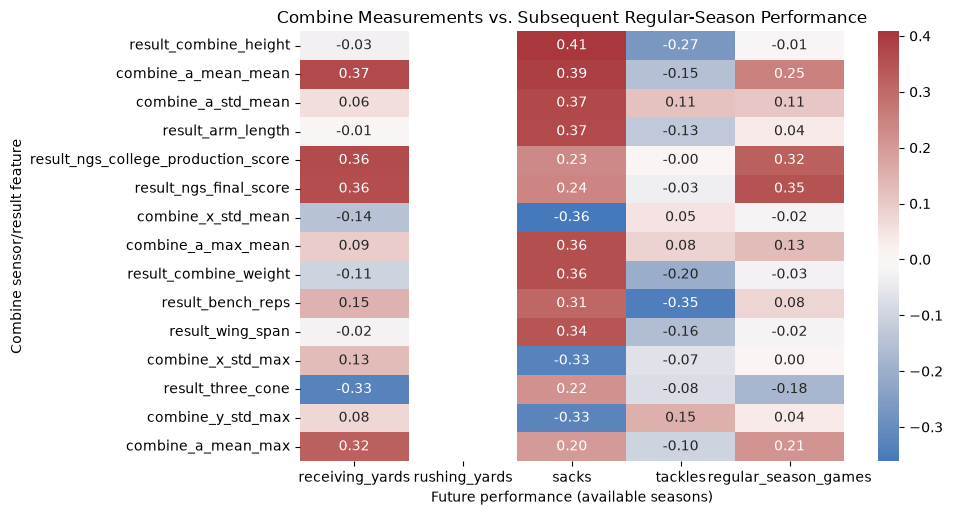

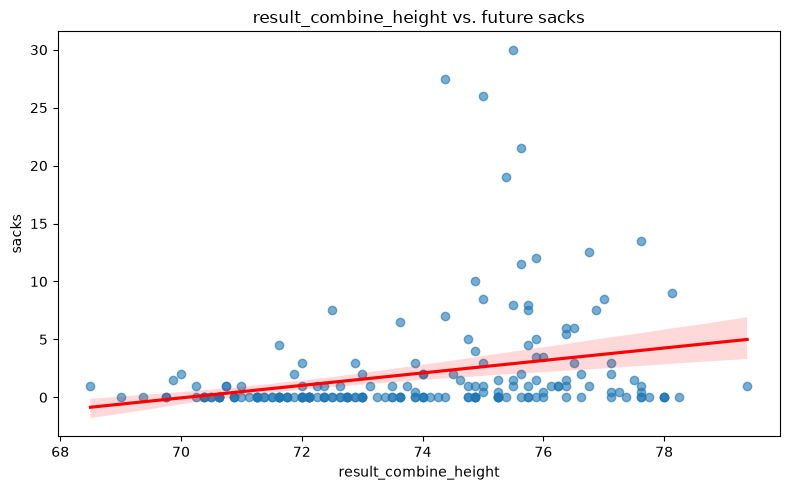

In [31]:
# Visualize sensor/performance relationships
target_cols = [
    c for c in ["receiving_yards", "rushing_yards", "sacks", "tackles",
                "regular_season_games"]
    if c in analysis_df.columns
]
sensor_feature_cols = [
    c for c in analysis_df.select_dtypes(include=np.number).columns
    if c.startswith("combine_") or c.startswith("result_")
]

if sensor_feature_cols and target_cols:
    correlations = analysis_df[sensor_feature_cols + target_cols].corr(method="spearman")
    relationship_corr = correlations.loc[sensor_feature_cols, target_cols]
    strongest = (
        relationship_corr.stack()
        .rename("spearman_correlation")
        .to_frame()
        .assign(abs_correlation=lambda d: d["spearman_correlation"].abs())
        .sort_values("abs_correlation", ascending=False)
    )
    print("Strongest combine-feature / future-performance associations:")
    display(strongest.head(20).drop(columns="abs_correlation"))

    # Compact heatmap of the strongest sensor features against performance targets.
    top_features = (
        relationship_corr.abs().max(axis=1)
        .sort_values(ascending=False)
        .head(15)
        .index
    )
    plt.figure(figsize=(10, max(5, 0.35 * len(top_features))))
    sns.heatmap(
        relationship_corr.loc[top_features],
        cmap="vlag",
        center=0,
        annot=True,
        fmt=".2f"
    )
    plt.title("Combine Measurements vs. Subsequent Regular-Season Performance")
    plt.xlabel("Future performance (available seasons)")
    plt.ylabel("Combine sensor/result feature")
    plt.tight_layout()
    plt.show()

    # Scatter plot for the strongest observed association.
    best_feature, best_target = strongest.index[0]
    plot_data = analysis_df[[best_feature, best_target]].dropna()
    if len(plot_data) > 2:
        plt.figure(figsize=(8, 5))
        sns.regplot(
            data=plot_data,
            x=best_feature,
            y=best_target,
            scatter_kws={"alpha": 0.6},
            line_kws={"color": "red"}
        )
        plt.title(f"{best_feature} vs. future {best_target}")
        plt.tight_layout()
        plt.show()
else:
    print("Not enough numeric combine features or performance targets to plot.")

### Evaluation

In [32]:
# Compare combine movement summaries with traditional drill times and future outcomes
movement_features = [
    c for c in analysis_df.select_dtypes(include=np.number).columns
    if c.startswith(("combine_s_", "combine_a_", "combine_dis_", "combine_dir_"))
]

drill_times = [
    c for c in ["result_ten_yd_split", "result_forty",
                "result_three_cone", "result_short_shuttle"]
    if c in analysis_df.columns
]

future_outcomes = [
    c for c in ["receiving_yards", "rushing_yards", "sacks",
                "tackles", "regular_season_games"]
    if c in analysis_df.columns
]

Spearman correlations: combine movement summaries vs. drill times


,result_ten_yd_split,result_forty,result_three_cone,result_short_shuttle
combine_s_mean_mean,-0.80,-0.79,-0.80,-0.72
combine_s_mean_max,-0.82,-0.87,-0.66,-0.63
combine_s_std_mean,-0.75,-0.76,-0.71,-0.63
combine_s_std_max,-0.77,-0.81,-0.69,-0.63
combine_s_max_mean,-0.81,-0.80,-0.78,-0.70
combine_s_max_max,-0.82,-0.88,-0.69,-0.64
combine_a_mean_mean,-0.20,-0.28,-0.54,-0.45
combine_a_mean_max,-0.26,-0.29,-0.72,-0.68
combine_a_std_mean,-0.40,-0.44,-0.58,-0.49
combine_a_std_max,-0.48,-0.47,-0.70,-0.63


Movement metrics with relatively stronger outcome associations than drill-time associations:


,movement_feature,strongest_drill,drill_rho,strongest_future_outcome,outcome_rho,outcome_vs_drill_abs_diff
20,combine_dir_std_mean,result_ten_yd_split,0.23,sacks,0.30,0.07
22,combine_dir_max_mean,result_ten_yd_split,0.40,sacks,0.29,-0.11
6,combine_a_mean_mean,result_three_cone,-0.54,sacks,0.39,-0.15
8,combine_a_std_mean,result_three_cone,-0.58,sacks,0.37,-0.22
23,combine_dir_max_max,result_ten_yd_split,-0.40,receiving_yards,0.14,-0.26
19,combine_dir_mean_max,result_three_cone,0.54,sacks,-0.28,-0.26
18,combine_dir_mean_mean,result_three_cone,0.50,tackles,0.24,-0.26
10,combine_a_max_mean,result_three_cone,-0.68,sacks,0.36,-0.32
21,combine_dir_std_max,result_three_cone,-0.63,sacks,-0.24,-0.38
7,combine_a_mean_max,result_three_cone,-0.72,receiving_yards,0.32,-0.40


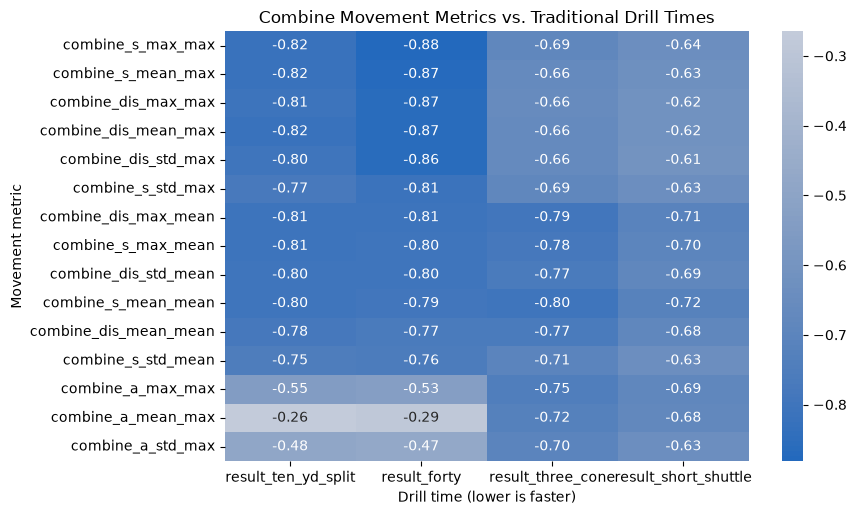

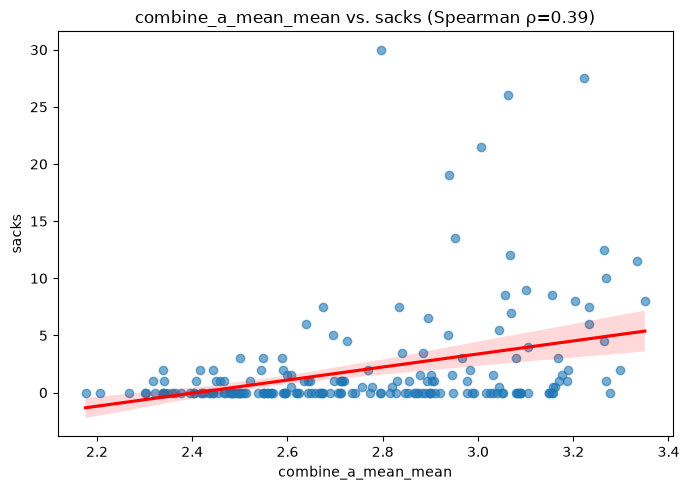

In [33]:
if not movement_features or not drill_times:
    print("Movement features or traditional drill times are unavailable.")
else:
    movement_drill_corr = (
        analysis_df[movement_features + drill_times]
        .corr(method="spearman")
        .loc[movement_features, drill_times]
    )

    print("Spearman correlations: combine movement summaries vs. drill times")
    display(movement_drill_corr.round(2))

    if future_outcomes:
        movement_outcome_corr = (
            analysis_df[movement_features + future_outcomes]
            .corr(method="spearman")
            .loc[movement_features, future_outcomes]
        )

        # Rank metrics by outcome association relative to their strongest drill-time association.
        comparison_rows = []
        for feature in movement_features:
            drill_series = movement_drill_corr.loc[feature].dropna()
            outcome_series = movement_outcome_corr.loc[feature].dropna()

            if drill_series.empty or outcome_series.empty:
                continue

            strongest_drill = np.abs(drill_series).idxmax()
            strongest_outcome = np.abs(outcome_series).idxmax()
            drill_strength = np.abs(drill_series[strongest_drill])
            outcome_strength = np.abs(outcome_series[strongest_outcome])

            comparison_rows.append({
                "movement_feature": feature,
                "strongest_drill": strongest_drill,
                "drill_rho": drill_series[strongest_drill],
                "strongest_future_outcome": strongest_outcome,
                "outcome_rho": outcome_series[strongest_outcome],
                "outcome_vs_drill_abs_diff": outcome_strength - drill_strength,
            })

        comparison = (
            pd.DataFrame(comparison_rows)
            .sort_values("outcome_vs_drill_abs_diff", ascending=False)
        )
        print("Movement metrics with relatively stronger outcome associations than drill-time associations:")
        display(comparison.head(15).round(2))

        # Visualize the strongest movement/drill-time relationships.
        plt.figure(figsize=(9, max(5, 0.35 * min(15, len(movement_features)))))
        sns.heatmap(
            movement_drill_corr.loc[
                movement_drill_corr.abs().max(axis=1)
                .sort_values(ascending=False).head(15).index
            ],
            cmap="vlag",
            center=0,
            annot=True,
            fmt=".2f"
        )
        plt.title("Combine Movement Metrics vs. Traditional Drill Times")
        plt.xlabel("Drill time (lower is faster)")
        plt.ylabel("Movement metric")
        plt.tight_layout()
        plt.show()

        # Inspect the strongest movement/outcome pair.
        valid_outcome_corr = movement_outcome_corr.stack().dropna()
        if not valid_outcome_corr.empty:
            feature, outcome = valid_outcome_corr.abs().idxmax()
            plot_data = analysis_df[[feature, outcome]].dropna()

            if len(plot_data) > 2:
                plt.figure(figsize=(7, 5))
                sns.regplot(
                    data=plot_data,
                    x=feature,
                    y=outcome,
                    scatter_kws={"alpha": 0.6},
                    line_kws={"color": "red"}
                )
                plt.title(f"{feature} vs. {outcome} (Spearman ρ={valid_outcome_corr.loc[(feature, outcome)]:.2f})")
                plt.tight_layout()
                plt.show()

In [34]:
# Analyze combine movement profiles against rookie-season NFL performance.
# Uses existing combine_tracking_df, players_df, and seasonal_performance.

ct = combine_tracking_df.copy()

if "nfl_id" not in ct.columns:
    raise ValueError("combine_tracking_df must contain nfl_id.")

In [35]:
# Group frames into drill attempts when those identifiers are available.
id_keys = ["nfl_id"] + (["draft_year"] if "draft_year" in ct.columns else [])
sequence_keys = id_keys + [
    c for c in ["event", "event_id", "attempt"]
    if c in ct.columns
]
sequence_keys = list(dict.fromkeys(sequence_keys))

In [36]:
# Preserve frame order, or sort by a frame/time column if one exists.
order_col = next(
    (c for c in ["frame_id", "frame", "time"] if c in ct.columns), None
)
if order_col:
    ct = ct.sort_values(order_col, kind="stable")

attempt_metrics = []
for key, group in ct.groupby(sequence_keys, dropna=False, sort=False):
    if not isinstance(key, tuple):
        key = (key,)

    row = dict(zip(sequence_keys, key))
    metrics = {}

    for col in ["s", "a"]:
        if col in group.columns:
            values = pd.to_numeric(group[col], errors="coerce").dropna()
            if not values.empty:
                metrics[f"{col}_mean"] = values.mean()
                metrics[f"{col}_max"] = values.max()
                metrics[f"{col}_std"] = values.std()
                if col == "a":
                    metrics["positive_acceleration_fraction"] = (values > 0).mean()
                    metrics["acceleration_change_mean"] = values.diff().abs().mean()

    if "dir" in group.columns:
        direction = pd.to_numeric(group["dir"], errors="coerce").dropna().to_numpy()
        if len(direction) > 1:
            angle_change = np.abs(
                (np.diff(direction) + 180) % 360 - 180
            )
            metrics["turn_angle_mean"] = angle_change.mean()
            metrics["turn_angle_total"] = angle_change.sum()

    if {"x", "y"}.issubset(group.columns):
        xy = group[["x", "y"]].apply(pd.to_numeric, errors="coerce").dropna().to_numpy()
        if len(xy) > 1:
            step_distances = np.linalg.norm(np.diff(xy, axis=0), axis=1)
            path_length = step_distances.sum()
            displacement = np.linalg.norm(xy[-1] - xy[0])
            metrics["path_efficiency"] = (
                displacement / path_length if path_length > 0 else np.nan
            )

    if metrics:
        row.update(metrics)
        attempt_metrics.append(row)

In [37]:
attempt_df = pd.DataFrame(attempt_metrics)
if attempt_df.empty:
    raise ValueError("No usable movement measurements found in combine_tracking_df.")

metric_cols = [
    c for c in attempt_df.select_dtypes(include=np.number).columns
    if c not in id_keys
]
drill_features = (
    attempt_df.groupby(id_keys, dropna=False)[metric_cols]
    .agg(["mean", "max"])
)
drill_features.columns = [
    f"drill_{feature}_{stat}" for feature, stat in drill_features.columns
]
drill_features = drill_features.reset_index()

In [38]:
# Select each player's draft-year season as the rookie season.
player_draft_info = players_df[["nfl_id", "draft_year", "nfl_position"]].drop_duplicates()
rookie_performance = seasonal_performance.merge(
    player_draft_info, on="nfl_id", how="inner"
)
rookie_performance = rookie_performance[
    rookie_performance["_season"] == rookie_performance["draft_year"]
].copy()

rookie_analysis = rookie_performance.merge(
    drill_features, on=id_keys, how="inner"
)

performance_cols = [
    c for c in [
        "regular_season_plays", "regular_season_games", "targets",
        "receiving_yards", "rushing_yards", "sacks", "tackles",
        "tackles_for_loss", "forced_fumbles"
    ]
    if c in rookie_analysis.columns
]
drill_cols = [c for c in drill_features.columns if c.startswith("drill_")]

print(f"Players with both combine movement and rookie-season data: {len(rookie_analysis)}")

Players with both combine movement and rookie-season data: 378


Strongest movement-feature / rookie-performance associations:


,,spearman_rho
drill_s_mean_mean,targets,0.615583
drill_a_max_max,targets,0.490474
drill_s_max_max,targets,0.486522
drill_s_std_max,targets,0.471266
drill_a_std_max,targets,0.449995
drill_a_mean_max,targets,0.439119
drill_s_max_mean,targets,0.423019
drill_s_mean_max,targets,0.421060
drill_a_max_mean,targets,0.416121
drill_s_std_mean,targets,0.388961


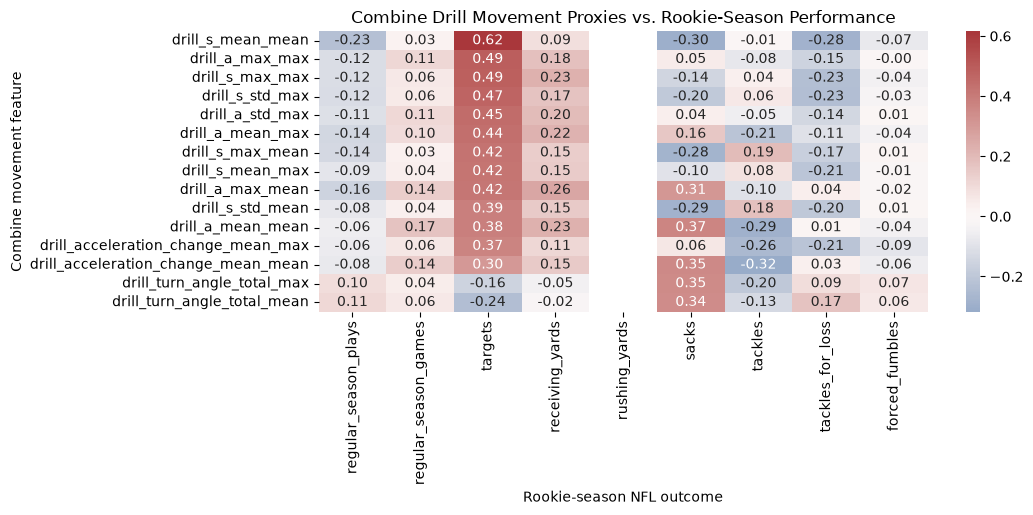

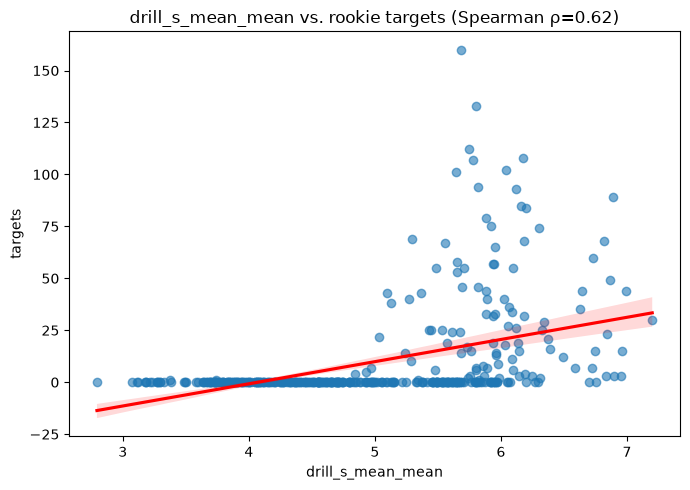

In [39]:
if drill_cols and performance_cols:
    corr = rookie_analysis[drill_cols + performance_cols].corr(
        method="spearman"
    ).loc[drill_cols, performance_cols]

    # Show the strongest observed associations.
    strongest = (
        corr.stack()
        .rename("spearman_rho")
        .to_frame()
        .assign(abs_rho=lambda d: d["spearman_rho"].abs())
        .sort_values("abs_rho", ascending=False)
    )
    print("Strongest movement-feature / rookie-performance associations:")
    display(strongest.head(15).drop(columns="abs_rho"))

    # Heatmap for features with the strongest association to any outcome.
    top_drill_features = (
        corr.abs().max(axis=1).sort_values(ascending=False).head(15).index
    )
    plt.figure(figsize=(11, max(5, 0.35 * len(top_drill_features))))
    sns.heatmap(
        corr.loc[top_drill_features],
        cmap="vlag",
        center=0,
        annot=True,
        fmt=".2f"
    )
    plt.title("Combine Drill Movement Proxies vs. Rookie-Season Performance")
    plt.xlabel("Rookie-season NFL outcome")
    plt.ylabel("Combine movement feature")
    plt.tight_layout()
    plt.show()

    # Plot the strongest pair with available observations.
    if not strongest.empty:
        best_feature, best_outcome = strongest.index[0]
        plot_data = rookie_analysis[[best_feature, best_outcome]].dropna()
        if len(plot_data) > 2:
            plt.figure(figsize=(7, 5))
            sns.regplot(
                data=plot_data,
                x=best_feature,
                y=best_outcome,
                scatter_kws={"alpha": 0.6},
                line_kws={"color": "red"}
            )
            plt.title(
                f"{best_feature} vs. rookie {best_outcome} "
                f"(Spearman ρ={strongest.iloc[0]['spearman_rho']:.2f})"
            )
            plt.tight_layout()
            plt.show()
else:
    print("Not enough movement features or rookie outcomes to calculate correlations.")